# Time Series Data Cleaning Pipeline

This notebook demonstrates a comprehensive pipeline for cleaning time series data using PyCaret's low-code approach and custom preprocessing steps.

## 1. Import Required Libraries

In [1]:
# Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pycaret.time_series import *
from pycaret.datasets import get_data
import warnings
warnings.filterwarnings('ignore')

print("Libraries imported successfully!")

Libraries imported successfully!


## 2. Load and Inspect Raw Data

Period
1949-01    112.0
1949-02    118.0
1949-03    132.0
1949-04    129.0
1949-05    121.0
Freq: M, Name: Number of airline passengers, dtype: float64

Raw data shape: (144,)

First 5 rows:
Period
1949-01-01    112.0
1949-02-01    118.0
1949-03-01    132.0
1949-04-01    129.0
1949-05-01    121.0
Freq: MS, Name: Number of airline passengers, dtype: float64

Data info:
<class 'pandas.core.series.Series'>
DatetimeIndex: 144 entries, 1949-01-01 to 1960-12-01
Freq: MS
Series name: Number of airline passengers
Non-Null Count  Dtype  
--------------  -----  
144 non-null    float64
dtypes: float64(1)
memory usage: 2.2 KB
None

Missing values:
0


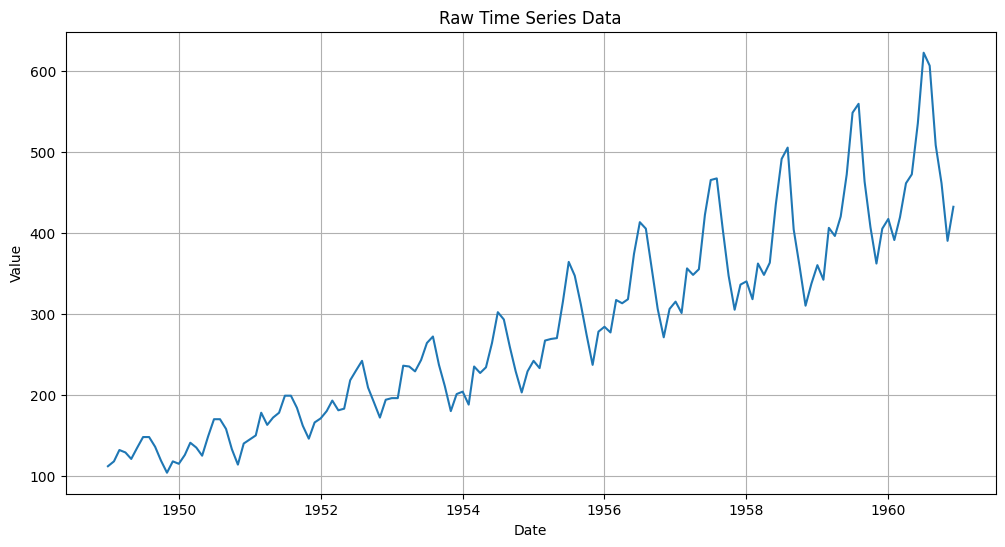

In [2]:
# Load sample time series data
data = get_data('airline')
data.index = data.index.to_timestamp()  # Convert to datetime for plotting

print("Raw data shape:", data.shape)
print("\nFirst 5 rows:")
print(data.head())
print("\nData info:")
print(data.info())
print("\nMissing values:")
print(data.isnull().sum())

# Visualize raw data
plt.figure(figsize=(12, 6))
plt.plot(data.index, data.values)
plt.title('Raw Time Series Data')
plt.xlabel('Date')
plt.ylabel('Value')
plt.grid(True)
plt.show()

## 3. Identify Data Quality Issues

Missing values per column:
0

Number of duplicate rows: 26

Potential outliers per column: 0

Data types:
float64

Statistical summary:
count    144.000000
mean     280.298611
std      119.966317
min      104.000000
25%      180.000000
50%      265.500000
75%      360.500000
max      622.000000
Name: Number of airline passengers, dtype: float64


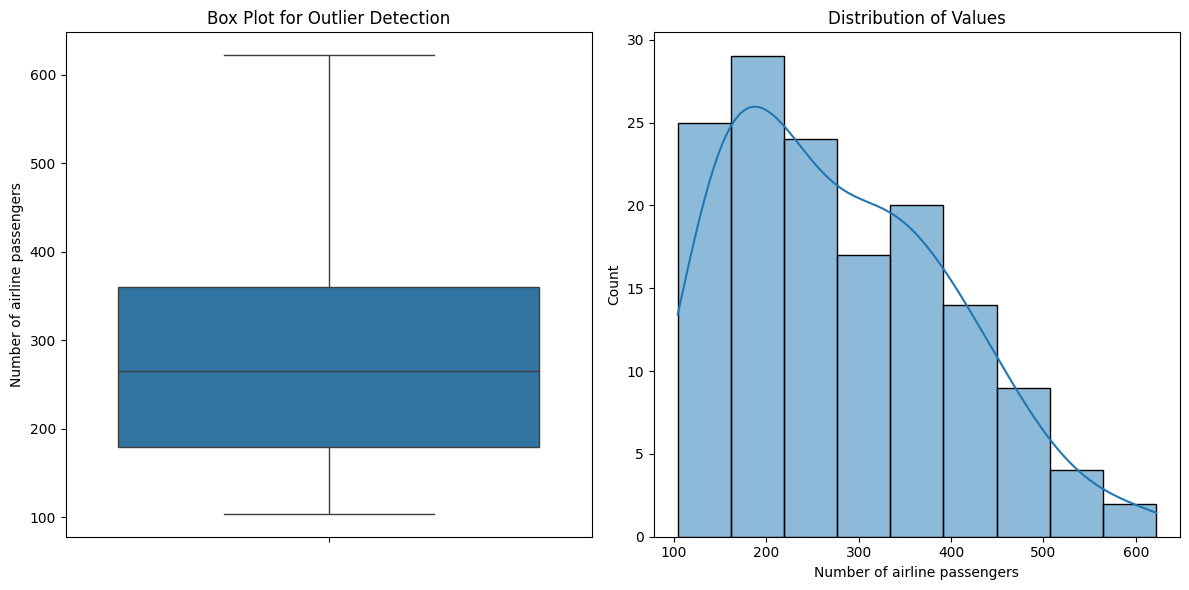

In [3]:
# Check for missing values
missing_values = data.isnull().sum()
print("Missing values per column:")
print(missing_values)

# Check for duplicates
duplicates = data.duplicated().sum()
print(f"\nNumber of duplicate rows: {duplicates}")

# Check for outliers using IQR method
Q1 = data.quantile(0.25)
Q3 = data.quantile(0.75)
IQR = Q3 - Q1
outliers = ((data < (Q1 - 1.5 * IQR)) | (data > (Q3 + 1.5 * IQR))).sum()
print(f"\nPotential outliers per column: {outliers}")

# Check data types and ranges
print("\nData types:")
print(data.dtypes)
print("\nStatistical summary:")
print(data.describe())

# Visualise distribution and outliers
plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
sns.boxplot(data=data)
plt.title('Box Plot for Outlier Detection')

plt.subplot(1, 2, 2)
sns.histplot(data=data, kde=True)
plt.title('Distribution of Values')
plt.tight_layout()
plt.show()

## 4. Custom Data Cleaning Pipeline

In [4]:
def handle_missing_values(data):
    """Handle missing values using forward fill, backward fill, or interpolation"""
    # First try forward fill
    data_clean = data.fillna(method='ffill')
    # Then backward fill for any remaining NaNs
    data_clean = data_clean.fillna(method='bfill')
    # Finally interpolate for time series
    data_clean = data_clean.interpolate(method='time')
    return data_clean


In [5]:

def remove_outliers_iqr(data, threshold=1.5):
    """Remove outliers using IQR method"""
    Q1 = data.quantile(0.25)
    Q3 = data.quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - threshold * IQR
    upper_bound = Q3 + threshold * IQR
    return data.clip(lower=lower_bound, upper=upper_bound)


In [6]:

def remove_outliers_zscore(data, threshold=3):
    """Remove outliers using Z-score method"""
    mean_val = data.mean()
    std_val = data.std()
    z_scores = (data - mean_val) / std_val
    return data[abs(z_scores) < threshold]


In [8]:

def normalize_standard(data):
    """Normalize data using standard scaling (z-score)"""
    mean_val = data.mean()
    std_val = data.std()
    return (data - mean_val) / std_val


In [9]:

def normalize_minmax(data):
    """Normalize data using min-max scaling"""
    min_val = data.min()
    max_val = data.max()
    return (data - min_val) / (max_val - min_val)


In [10]:

def clean_pipeline(data, handle_missing=True, remove_outliers=True,
                  normalize=False, outlier_method='iqr', normalize_method='standard'):
    """Complete cleaning pipeline using standalone functions"""
    print("Starting data cleaning pipeline...")

    if handle_missing:
        data = handle_missing_values(data)
        print("Missing values handled.")

    if remove_outliers:
        if outlier_method == 'iqr':
            data = remove_outliers_iqr(data)
        elif outlier_method == 'zscore':
            data = remove_outliers_zscore(data)
        print("Outliers removed.")

    if normalize:
        if normalize_method == 'standard':
            data = normalize_standard(data)
        elif normalize_method == 'minmax':
            data = normalize_minmax(data)
        print("Data normalized.")

    print("Data cleaning pipeline completed.")
    return data

# Apply custom cleaning pipeline
data_clean_custom = clean_pipeline(data.copy(), normalize=False)

print("\nCleaned data shape:", data_clean_custom.shape)
print("Missing values after cleaning:", data_clean_custom.isnull().sum().sum())

Starting data cleaning pipeline...
Missing values handled.
Outliers removed.
Data cleaning pipeline completed.

Cleaned data shape: (144,)
Missing values after cleaning: 0


## 5. PyCaret Data Cleaning Approach

In [11]:
# PyCaret approach - setup handles preprocessing automatically
from pycaret.time_series import TSForecastingExperiment

# Create experiment and setup (this includes data cleaning/preprocessing)
exp = TSForecastingExperiment()
exp.setup(data, fh=12, seasonal_period=12, verbose=True)

# Get the preprocessed data
data_clean_pycaret = exp.get_config('y')

print("PyCaret cleaned data shape:", data_clean_pycaret.shape)
print("PyCaret cleaned data type:", type(data_clean_pycaret))
print("\nFirst 5 rows of cleaned data:")
print(data_clean_pycaret.head())

ImportError: cannot import name 'TSForecastingExperiment' from 'pycaret.time_series' (/opt/anaconda3/envs/lowcodeMLv2/lib/python3.11/site-packages/pycaret/time_series/__init__.py)

## 6. Compare Cleaning Approaches

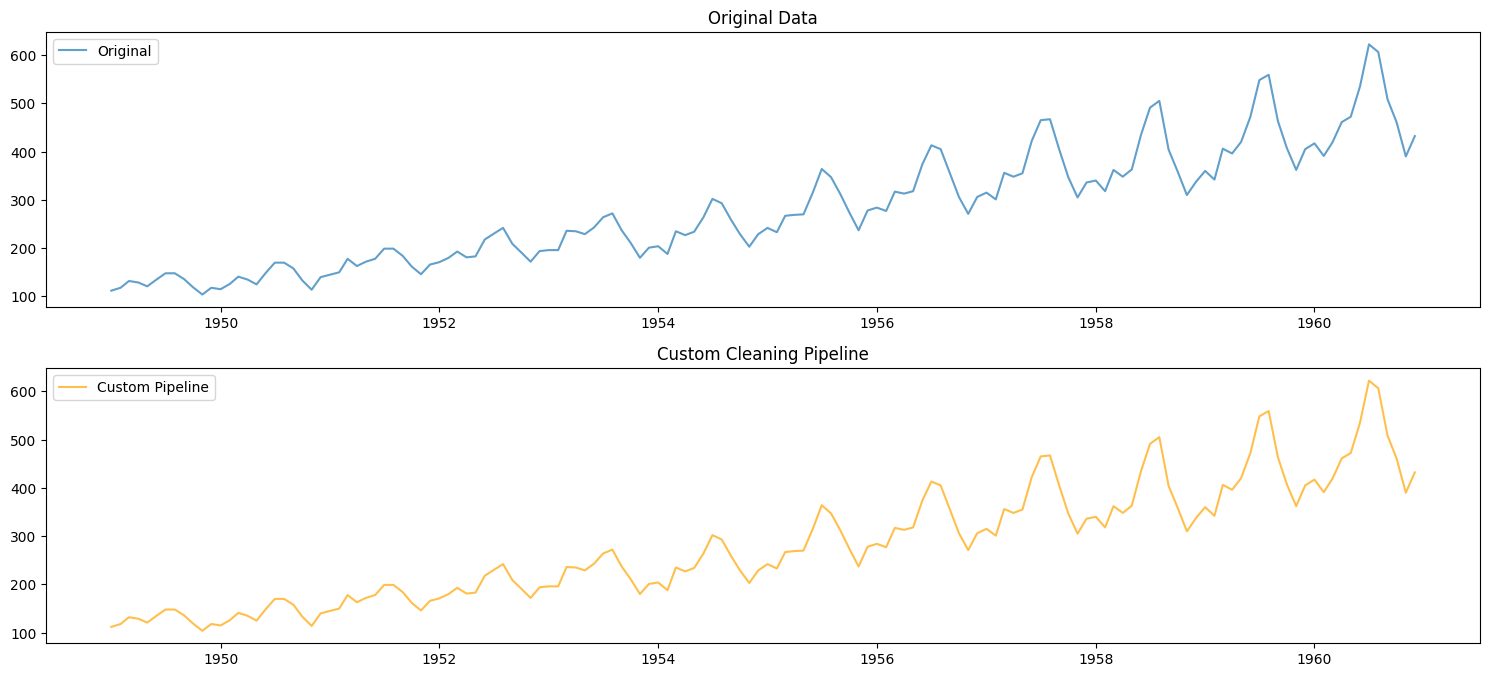

Statistical Summary Comparison:

Original Data:
count    144.000000
mean     280.298611
std      119.966317
min      104.000000
25%      180.000000
50%      265.500000
75%      360.500000
max      622.000000
Name: Number of airline passengers, dtype: float64

Custom Pipeline Cleaned:
count    144.000000
mean     280.298611
std      119.966317
min      104.000000
25%      180.000000
50%      265.500000
75%      360.500000
max      622.000000
Name: Number of airline passengers, dtype: float64

PyCaret Cleaned:


NameError: name 'data_clean_pycaret' is not defined

In [12]:
# Compare original vs cleaned data
plt.figure(figsize=(15, 10))

plt.subplot(3, 1, 1)
plt.plot(data.index, data.values, label='Original', alpha=0.7)
plt.title('Original Data')
plt.legend()

plt.subplot(3, 1, 2)
plt.plot(data_clean_custom.index, data_clean_custom.values, label='Custom Pipeline', color='orange', alpha=0.7)
plt.title('Custom Cleaning Pipeline')
plt.legend()



plt.tight_layout()
plt.show()

# Statistical comparison
print("Statistical Summary Comparison:")
print("\nOriginal Data:")
print(data.describe())
print("\nCustom Pipeline Cleaned:")
print(data_clean_custom.describe())
print("\nPyCaret Cleaned:")
print(data_clean_pycaret.describe())

## 8. Conclusion and Best Practices

In [13]:
print("""
Time Series Data Cleaning Summary:

1. Custom Pipeline Approach:
   - Pros: Full control, customizable, transparent
   - Cons: More code, potential for errors
   - Best for: Specific domain requirements

2. PyCaret Approach:
   - Pros: Low-code, automated, integrated with modeling
   - Cons: Less control, black-box elements
   - Best for: Quick prototyping, standard preprocessing

Best Practices:
- Always backup original data
- Document cleaning steps
- Validate after each cleaning step
- Consider domain knowledge for outlier detection
- Test stationarity for forecasting models
- Use appropriate imputation methods for time series

Choose the approach based on your project needs:
- Use PyCaret for rapid development and standard workflows
- Use custom pipeline for specialized requirements or when you need full control
""")

# Save cleaned data
data_clean_custom.to_csv('cleaned_data_custom.csv')
data_clean_pycaret.to_csv('cleaned_data_pycaret.csv')
print("Cleaned datasets saved to CSV files.")


Time Series Data Cleaning Summary:

1. Custom Pipeline Approach:
   - Pros: Full control, customizable, transparent
   - Cons: More code, potential for errors
   - Best for: Specific domain requirements

2. PyCaret Approach:
   - Pros: Low-code, automated, integrated with modeling
   - Cons: Less control, black-box elements
   - Best for: Quick prototyping, standard preprocessing

Best Practices:
- Always backup original data
- Document cleaning steps
- Validate after each cleaning step
- Consider domain knowledge for outlier detection
- Test stationarity for forecasting models
- Use appropriate imputation methods for time series

Choose the approach based on your project needs:
- Use PyCaret for rapid development and standard workflows
- Use custom pipeline for specialized requirements or when you need full control



NameError: name 'data_clean_pycaret' is not defined